Finite-difference reference solver for the 1D viscous Burgers' equation:

u_t + u*u_x = nu* u_xx, x in [-1,1], t in [0,1]

u(x,0) = -sin(pi*x)

u(-1,t) = u(1,t) = 0

The standard benchmark problem from Raissi, Perdikaris & Karniadakis (2019), "Physics-Informed Neural Networks". nu = 0.01/pi gives a solution that develops a sharp near-discontinuity around x=0 as t increases, which makes it a nontrivial test for a PINN.


In [18]:
import numpy as np

nu = 0.01/np.pi

def solve_burgers_fd(nx: int=401, nt:int=4000, x_range=(-1.0, 1.0), t_max:float=1.0):
  """
  Solve viscous Burgers' equation with explicit finite differences

  Returns
  x: (nx,) array of spatial grid points
  t: (nt+1, array of time grid points
  u: (nt+1, nx) array, u[i,j]=u(x[j], t[i])
  """

  x = np.linspace(x_range[0],x_range[1], nx)
  dx = x[1] - x[0]

  ##Explicit scheme stability: dt must be small relative to dx^2 (diffusion) and dx (advection)
  ##Pick dt conservatively and re-derive nt from it
  dt_diffusion_limit = 0.4 * dx**2 / nu
  dt = min(dt_diffusion_limit, t_max / nt)
  n_steps = int(np.ceil(t_max / dt))
  dt = t_max / n_steps

  u = np.zeros((n_steps + 1, nx))
  u[0] = -np.sin(np.pi * x)
  u[0, 0] = 0.0
  u[0, -1] = 0.0

  for n in range(n_steps):
      un = u[n]
      u_next = un.copy()

      # Central-difference diffusion term for all interior points
      diffusion = nu * (un[2:] - 2 * un[1:-1] + un[:-2]) / dx**2

      # Upwind advection term (Burgers' flux is nonlinear, so upwind
      # direction depends on the local sign of u)
      du_dx_backward = (un[1:-1] - un[:-2]) / dx
      du_dx_forward = (un[2:] - un[1:-1]) / dx
      advection = np.where(
          un[1:-1] >= 0,
          un[1:-1] * du_dx_backward,
          un[1:-1] * du_dx_forward,
      )

      u_next[1:-1] = un[1:-1] + dt * (-advection + diffusion)
      u_next[0] = 0.0
      u_next[-1] = 0.0
      u[n + 1] = u_next


   ##Subsample time axis down to a manageable number of stored snapshots
  stride = max(1, n_steps // nt)
  t_full = np.linspace(0, t_max, n_steps + 1)
  idx = np.arange(0, n_steps + 1, stride)
  if idx[-1] != n_steps:
      idx = np.append(idx, n_steps)

  return x, t_full[idx], u[idx]

In [19]:
if __name__ == "__main__":
    x, t, u = solve_burgers_fd()
    print(f"Solved on grid: {len(x)} x-points x {len(t)} t-points")
    print(f"u range: [{u.min():.4f}, {u.max():.4f}]")
    np.savez("fd_reference.npz", x=x, t=t, u=u)
    print("Saved reference solution to fd_reference.npz")

Solved on grid: 401 x-points x 4001 t-points
u range: [-1.0000, 1.0000]
Saved reference solution to fd_reference.npz


Training a neural network to satisfy the PDE directly. Using automatic differentiation to compute the physics loss (residual of the heat equation) rather than needing labelled data at all.

Unlike a standard surrogate model, this network is trained to satisfy three things simultaneously:

1. The initial condition, u(x,0) = -sin(pi x)

2. The boundary conditions, u(-1,t) = u(1,t) = 0

3. The PDE residual itself, u_t + u*u_x - nu*u_xx = 0, evaluated at randomly sampled "collocation" points throughout the domain interior.

In [29]:
import torch
import torch.nn as nn
import numpy as np

In [30]:
'''
Finite-difference reference solver for 1D viscous Burgers' equation:

u_t + u * u_x = nu * u_xx, x in [-1, 1], t in [0, 1]
u(x, 0) = -sin(pi*x)
u(-1, t) = u(1,t) = 0
'''

nu = 0.01/np.pi

class PINN(nn.Module):
  def __init__(self, n_hidden=6, width=32):
    super().__init__()
    layers = [nn.Linear(2,width), nn.Tanh()]
    for _ in range(n_hidden - 1):
      layers += [nn.Linear(width, width), nn.Tanh()]
    layers += [nn.Linear(width, 1)]
    self.net = nn.Sequential(*layers)

  def forward(self,x,t):
    xt = torch.cat([x,t], dim=1)
    return self.net(xt)

In [31]:
def pde_residual(model, x, t):
  """
  Compute the Burgers' equation residual u_t + u*u_x - nu*u_xx at (x,t)
  using automatic differentiation through the network.
  """
  x.requires_grad_(True)
  t.requires_grad_(True)
  u = model(x,t)

  u_t = torch.autograd.grad(u,t,grad_outputs=torch.ones_like(u), create_graph=True)[0]
  u_x = torch.autograd.grad(u,x,grad_outputs=torch.ones_like(u), create_graph=True)[0]
  u_xx = torch.autograd.grad(u_x,x,grad_outputs=torch.ones_like(u_x), create_graph=True)[0]

  return u_t + u*u_x - nu*u_xx

In [32]:
def train_pinn(
    n_collocation=10000,
    n_ic=200,
    n_bc=200,
    epochs=8000,
    lr=1e-3,
    device=None,
    log_every=500,
):
  device = device or ("cuda" if torch.cuda.is_available() else "cpu")
  print(f"Training on device: {device}")

  model = PINN().to(device)
  optimizer = torch.optim.Adam(model.parameters(),lr=lr)

  ##Collocation points: sampled randomly across the interior of the domain
  ##Enforce PDE residual=0
  x_f = (torch.rand(n_collocation, 1)*2-1).to(device)
  t_f = torch.rand(n_collocation, 1).to(device)

  ##Initial condition points: t=0, u=-sin(pi x)
  x_ic = (torch.rand(n_ic,1)*2-1).to(device)
  t_ic = torch.zeros(n_ic,1).to(device)
  u_ic = -torch.sin(np.pi*x_ic)

  ##Boundary condition points: x=-1 and x=1, u=0
  t_bc = torch.rand(n_bc,1).to(device)
  x_bc_left = -torch.ones(n_bc,1).to(device)
  x_bc_right = torch.ones(n_bc,1).to(device)

  mse = nn.MSELoss()
  history = {"total": [], "pde": [], "ic": [], "bc": []}

  for epoch in range(epochs):
    optimizer.zero_grad()
    residual = pde_residual(model,x_f.clone(), t_f.clone())
    loss_pde = mse(residual, torch.zeros_like(residual))

    u_pred_ic = model(x_ic, t_ic)
    loss_ic = mse(u_pred_ic, u_ic)

    u_pred_bc_left = model(x_bc_left, t_bc)
    u_pred_bc_right = model(x_bc_right, t_bc)
    loss_bc = mse(u_pred_bc_left, torch.zeros_like(u_pred_bc_left)) + \
              mse(u_pred_bc_right, torch.zeros_like(u_pred_bc_right))

    loss = loss_pde + loss_ic + loss_bc
    loss.backward()
    optimizer.step()

    history["total"].append(loss.item())
    history["pde"].append(loss_pde.item())
    history["ic"].append(loss_ic.item())
    history["bc"].append(loss_bc.item())

    if epoch % log_every == 0 or epoch == epochs -1:
      print(f"epoch {epoch:5d}; total {loss.item():.3e}"
      f"pde {loss_pde.item():.3e}; ic {loss_ic.item():.3e}; bc {loss_bc.item():.3e}")

  return model, history, device

Training the PINN, evaluating it against the finite-difference reference solution, times both and producing comparison plots.

Usage:
python solver.py  - generates fd_reference.npz (run once)

python train.py  - trains PINN, evaluates, plots


In [33]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch


Loaded FD reference: (4001, 401) grid
FD solver time (full grid): 0.2631s
Training on device: cpu
epoch     0; total 5.400e-01pde 5.276e-06; ic 5.147e-01; bc 2.529e-02
epoch   500; total 1.052e-01pde 4.418e-02; ic 5.833e-02; bc 2.644e-03
epoch  1000; total 8.325e-02pde 3.259e-02; ic 5.038e-02; bc 2.800e-04
epoch  1500; total 4.535e-02pde 1.847e-02; ic 2.666e-02; bc 2.207e-04
epoch  2000; total 2.036e-02pde 9.439e-03; ic 1.078e-02; bc 1.387e-04
epoch  2500; total 2.756e-02pde 2.167e-02; ic 5.495e-03; bc 4.019e-04
epoch  3000; total 5.392e-03pde 3.288e-03; ic 2.034e-03; bc 6.993e-05
epoch  3500; total 4.048e-03pde 2.580e-03; ic 1.430e-03; bc 3.733e-05
epoch  4000; total 2.883e-03pde 1.825e-03; ic 1.031e-03; bc 2.738e-05
epoch  4500; total 2.042e-03pde 1.272e-03; ic 7.471e-04; bc 2.259e-05
epoch  5000; total 1.602e-03pde 1.032e-03; ic 5.524e-04; bc 1.759e-05
epoch  5500; total 1.299e-03pde 8.540e-04; ic 4.321e-04; bc 1.312e-05
epoch  6000; total 1.099e-03pde 7.347e-04; ic 3.544e-04; bc 1.

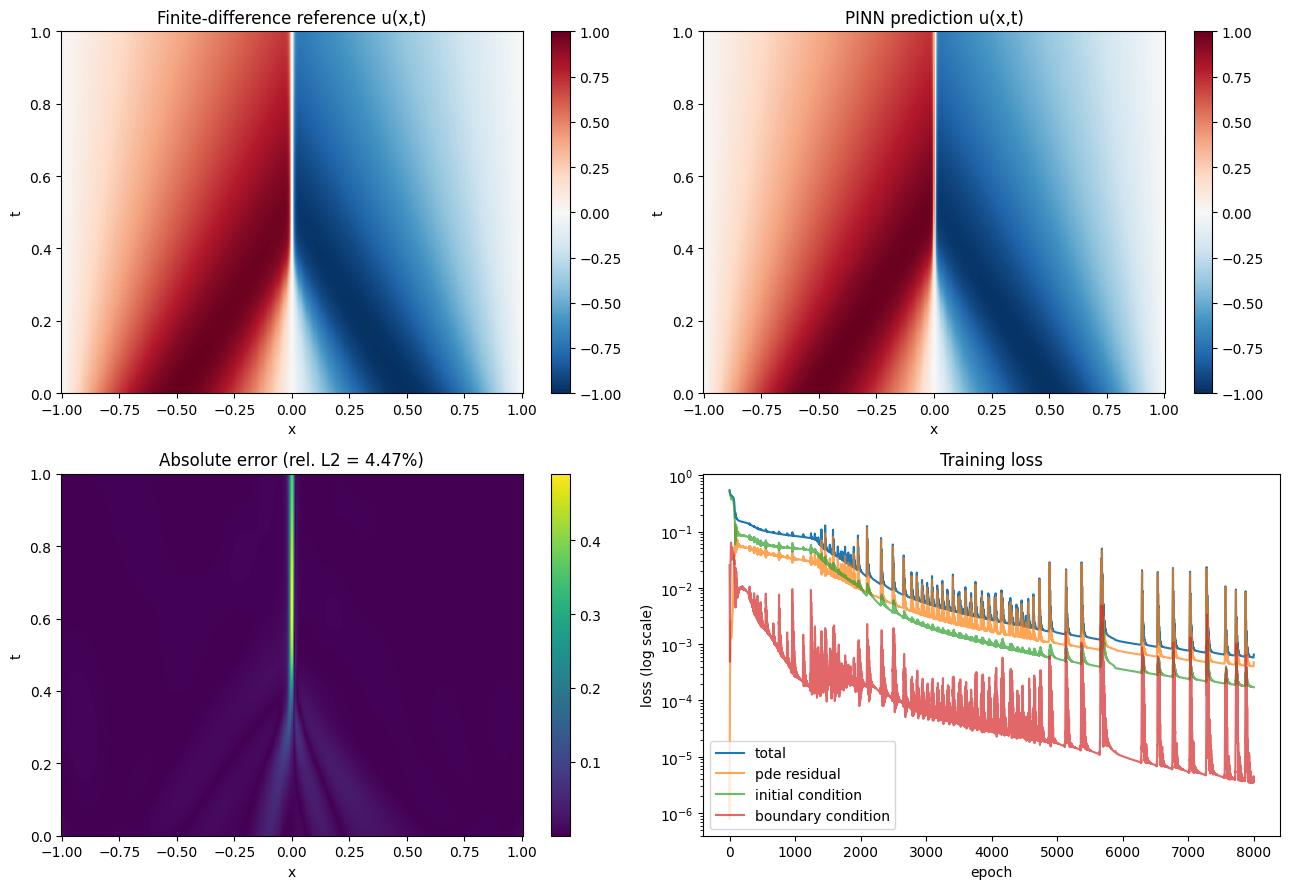

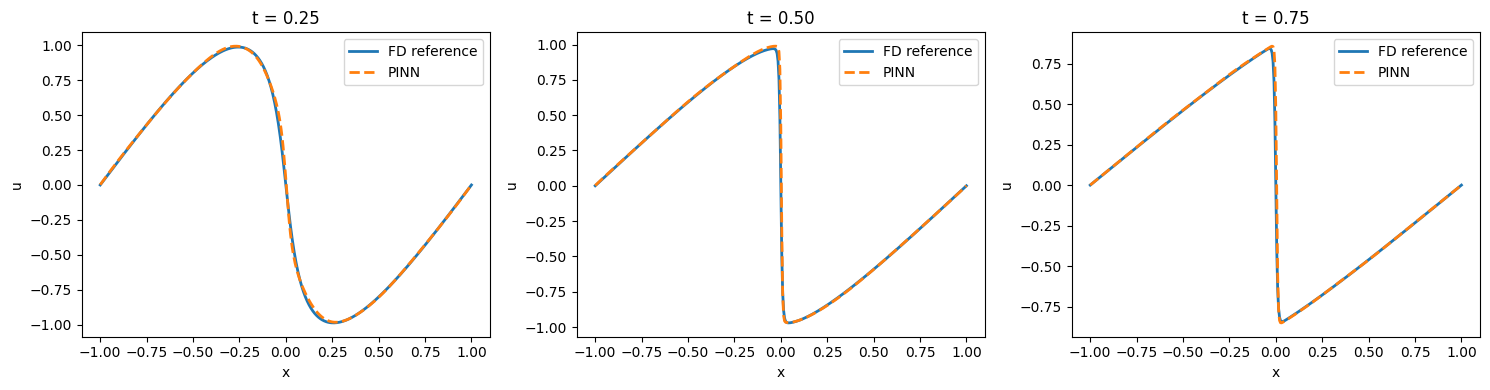

In [34]:
ref_file = 'fd_reference.npz'


torch.manual_seed(0)

np.random.seed(0)

def evaluate_on_grid(model, x, t, device):
    X, T = np.meshgrid(x, t)  # shape (nt, nx)
    x_flat = torch.tensor(X.flatten(), dtype=torch.float32).unsqueeze(1).to(device)
    t_flat = torch.tensor(T.flatten(), dtype=torch.float32).unsqueeze(1).to(device)

    model.eval()
    with torch.no_grad():
        u_flat = model(x_flat, t_flat).cpu().numpy()
    return u_flat.reshape(X.shape)


def main():
    data = np.load(ref_file)
    x, t, u_fd = data["x"], data["t"], data["u"]
    print(f"Loaded FD reference: {u_fd.shape} grid")

    t0 = time.perf_counter()
    solve_burgers_fd(nx=len(x), nt=len(t))
    fd_time = time.perf_counter() - t0
    print(f"FD solver time (full grid): {fd_time:.4f}s")

    t0 = time.perf_counter()
    model, history, device = train_pinn(epochs=8000)
    train_time = time.perf_counter() - t0
    print(f"PINN training time: {train_time:.2f}s on {device}")

    t0 = time.perf_counter()
    u_pinn = evaluate_on_grid(model, x, t, device)
    pinn_inference_time = time.perf_counter() - t0
    print(f"PINN inference time (full grid): {pinn_inference_time:.4f}s")

    error = np.abs(u_pinn - u_fd)
    l2_rel_error = np.linalg.norm(u_pinn - u_fd) / np.linalg.norm(u_fd)
    print(f"Relative L2 error vs FD reference: {l2_rel_error:.4%}")
    print(f"Max absolute error: {error.max():.4f}")
    print(f"Inference vs FD solve speedup (post-training): {fd_time / pinn_inference_time:.1f}x")

    fig, axes = plt.subplots(2, 2, figsize=(13, 9))

    im0 = axes[0, 0].pcolormesh(x, t, u_fd, shading="auto", cmap="RdBu_r", vmin=-1, vmax=1)
    axes[0, 0].set_title("Finite-difference reference u(x,t)")
    axes[0, 0].set_xlabel("x"); axes[0, 0].set_ylabel("t")
    fig.colorbar(im0, ax=axes[0, 0])

    im1 = axes[0, 1].pcolormesh(x, t, u_pinn, shading="auto", cmap="RdBu_r", vmin=-1, vmax=1)
    axes[0, 1].set_title("PINN prediction u(x,t)")
    axes[0, 1].set_xlabel("x"); axes[0, 1].set_ylabel("t")
    fig.colorbar(im1, ax=axes[0, 1])

    im2 = axes[1, 0].pcolormesh(x, t, error, shading="auto", cmap="viridis")
    axes[1, 0].set_title(f"Absolute error (rel. L2 = {l2_rel_error:.2%})")
    axes[1, 0].set_xlabel("x"); axes[1, 0].set_ylabel("t")
    fig.colorbar(im2, ax=axes[1, 0])

    axes[1, 1].semilogy(history["total"], label="total")
    axes[1, 1].semilogy(history["pde"], label="pde residual", alpha=0.7)
    axes[1, 1].semilogy(history["ic"], label="initial condition", alpha=0.7)
    axes[1, 1].semilogy(history["bc"], label="boundary condition", alpha=0.7)
    axes[1, 1].set_title("Training loss")
    axes[1, 1].set_xlabel("epoch"); axes[1, 1].set_ylabel("loss (log scale)")
    axes[1, 1].legend()

    plt.tight_layout()
    plt.savefig("results.png", dpi=150)
    print("Saved plots to results.png")

    fig2, axes2 = plt.subplots(1, 3, figsize=(15, 4))
    for ax, t_snap in zip(axes2, [0.25, 0.5, 0.75]):
        idx = np.argmin(np.abs(t - t_snap))
        ax.plot(x, u_fd[idx], label="FD reference", linewidth=2)
        ax.plot(x, u_pinn[idx], "--", label="PINN", linewidth=2)
        ax.set_title(f"t = {t[idx]:.2f}")
        ax.set_xlabel("x"); ax.set_ylabel("u")
        ax.legend()
    plt.tight_layout()
    plt.savefig("snapshots.png", dpi=150)
    print("Saved snapshot comparison to snapshots.png")

    with open("results_summary.txt", "w") as f:
        f.write(f"Device: {device}\n")
        f.write(f"FD solver time (grid {u_fd.shape}): {fd_time:.4f}s\n")
        f.write(f"PINN training time (8000 epochs): {train_time:.2f}s\n")
        f.write(f"PINN inference time (full grid): {pinn_inference_time:.4f}s\n")
        f.write(f"Relative L2 error vs FD: {l2_rel_error:.4%}\n")
        f.write(f"Max absolute error: {error.max():.4f}\n")
        f.write(f"Inference speedup vs re-solving: {fd_time / pinn_inference_time:.1f}x\n")


main()

In [35]:
data = np.load("fd_reference.npz")
x, t, u_fd = data["x"], data["t"], data["u"]

results = []
for seed in range(6):
    torch.manual_seed(seed)
    np.random.seed(seed)
    model, history, device = train_pinn(epochs=8000, log_every=100000)
    u_pinn = evaluate_on_grid(model, x, t, device)
    rel_l2 = np.linalg.norm(u_pinn - u_fd) / np.linalg.norm(u_fd)
    max_abs = np.abs(u_pinn - u_fd).max()
    results.append((seed, rel_l2, max_abs))
    print(f"seed {seed}: rel L2 = {rel_l2:.2%}, max abs = {max_abs:.3f}")

errs = [r[1] for r in results]
print(f"range {min(errs):.1%} to {max(errs):.1%}, mean {np.mean(errs):.1%}")

Training on device: cpu
epoch     0; total 5.400e-01pde 5.276e-06; ic 5.147e-01; bc 2.529e-02
epoch  7999; total 6.525e-04pde 4.764e-04; ic 1.721e-04; bc 3.969e-06
seed 0: rel L2 = 4.47%, max abs = 0.490
Training on device: cpu
epoch     0; total 5.709e-01pde 1.655e-06; ic 5.586e-01; bc 1.224e-02
epoch  7999; total 6.970e-04pde 4.305e-04; ic 2.607e-04; bc 5.775e-06
seed 1: rel L2 = 6.80%, max abs = 0.719
Training on device: cpu
epoch     0; total 5.612e-01pde 1.007e-04; ic 5.130e-01; bc 4.816e-02
epoch  7999; total 1.153e-03pde 7.985e-04; ic 3.417e-04; bc 1.264e-05
seed 2: rel L2 = 2.70%, max abs = 0.222
Training on device: cpu
epoch     0; total 5.656e-01pde 1.327e-04; ic 5.172e-01; bc 4.826e-02
epoch  7999; total 1.061e-03pde 7.687e-04; ic 1.750e-04; bc 1.170e-04
seed 3: rel L2 = 4.45%, max abs = 0.502
Training on device: cpu
epoch     0; total 5.228e-01pde 1.065e-03; ic 5.114e-01; bc 1.034e-02
epoch  7999; total 1.380e-03pde 8.289e-04; ic 5.462e-04; bc 5.099e-06
seed 4: rel L2 = 10.